# 02 · Aprendizaje no supervisado — Bike Sharing Demand

**Responsable:** Pardo · **Plan:** `project_plan_crisp_dm.md` §5 · `plan_sprints.md` §5 (Sprint 2) · Base: lab5 (clustering) y lab6 (PCA/UMAP).

**Preguntas:** ¿hay tipos de hora (arquetipos) reconocibles en las condiciones de calendario y clima? ¿Cuántos? ¿Son estables o un artefacto del algoritmo?

**Protocolo:**
- Solo **train** (2011-01-01 a 2012-06-30). El test no se usa; en el Sprint 3 se le **asignan** clusters con `predict`.
- Entradas (§5.1): `hr_sin`, `hr_cos`, `temp`, `hum`, `windspeed`, `workingday`. **Sin el target**: `cnt` solo se mira después, para interpretar.
- Imputación y escalado ajustados solo con train, dentro de un pipeline (`src/clustering.py`).
- Los clusters se tratan como **hipótesis de trabajo**, no como categorías reales (rúbrica: "evitar tratar clusters como categorías reales sin evidencia").

## 1) Preparación del entorno

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.clustering import VARIABLES, K_ELEGIDO, build_escalado, build_clustering

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "pardo" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
N_SIL = 6000   # silueta sobre una muestra fija (O(n²)); random_state=42

### ✅ Punto de control 1

In [2]:
assert RANDOM_STATE == 42
print("✅ Configuración lista. Variables:", VARIABLES)

✅ Configuración lista. Variables: ['hr_sin', 'hr_cos', 'temp', 'hum', 'windspeed', 'workingday']


## 2) Datos de train y escalado

In [3]:
X_tr, y_tr = separar_xy(temporal_split(load_data())[0])
escalado = build_escalado().fit(X_tr)          # medianas y escalas: solo train
Z = escalado.transform(X_tr)
print(f"Matriz para clustering: {Z.shape} | medias ≈ {Z.mean().abs().max():.1e}, std ≈ {Z.std().mean():.3f}")
print("hum imputada con la mediana de train:", round(float(escalado.named_steps['imputer'].statistics_[3]), 3))
Z.describe().round(2)

Matriz para clustering: (13003, 6) | medias ≈ 1.4e-16, std ≈ 1.000
hum imputada con la mediana de train: 0.62


,hr_sin,hr_cos,temp,hum,windspeed,workingday
count,13003.00,13003.00,13003.00,13003.00,13003.00,13003.00
mean,-0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.41,-1.41,-2.41,-2.75,-1.58,-1.47
25%,-0.99,-0.99,-0.85,-0.78,-0.74,-1.47
50%,0.01,0.01,-0.01,-0.02,-0.02,0.68
75%,1.01,1.01,0.83,0.84,0.70,0.68
max,1.42,1.42,2.61,1.90,5.27,0.68


**Por qué `hr_sin`/`hr_cos` y no `hr`:** con la hora entera, las 23 h y las 0 h quedarían a 23 unidades de distancia; en el círculo quedan vecinas. Ojo: ambas cuentan como 2 de 6 dimensiones, así que la hora pesa un tercio de la distancia.

## 3) Elección de k (K-Means, k = 2..12)

Criterios del plan (§5.3): inercia (codo), silueta (más alto es mejor), Davies-Bouldin (más bajo es mejor) y BIC del GMM.

In [4]:
filas = []
modelos_km, modelos_gmm = {}, {}
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(Z)
    modelos_km[k], modelos_gmm[k] = km, gmm
    filas.append({
        "k": k, "inercia": km.inertia_,
        "silueta": silhouette_score(Z, km.labels_, sample_size=N_SIL, random_state=RANDOM_STATE),
        "davies_bouldin": davies_bouldin_score(Z, km.labels_),
        "bic_gmm": gmm.bic(Z), "aic_gmm": gmm.aic(Z),
        "silueta_gmm": silhouette_score(Z, gmm.predict(Z), sample_size=N_SIL, random_state=RANDOM_STATE),
    })
eleccion = pd.DataFrame(filas).set_index("k")
eleccion.round(3)

,inercia,silueta,davies_bouldin,bic_gmm,aic_gmm,silueta_gmm
k,,,,,,
2,62321.000,0.194,1.945,211487.440,211076.428,0.178
3,53912.279,0.197,1.730,35930.062,35309.808,0.136
4,48590.307,0.177,1.624,28659.023,27829.527,0.114
5,44239.616,0.196,1.715,25527.405,24488.667,0.181
6,41059.503,0.190,1.654,18202.322,16954.342,0.092
7,38913.761,0.173,1.611,17274.368,15817.146,0.132
8,36635.045,0.182,1.590,7909.695,6243.230,0.123
9,34813.052,0.182,1.506,-2132.106,-4007.813,0.104
10,33239.648,0.184,1.530,-15880.198,-17965.147,0.101


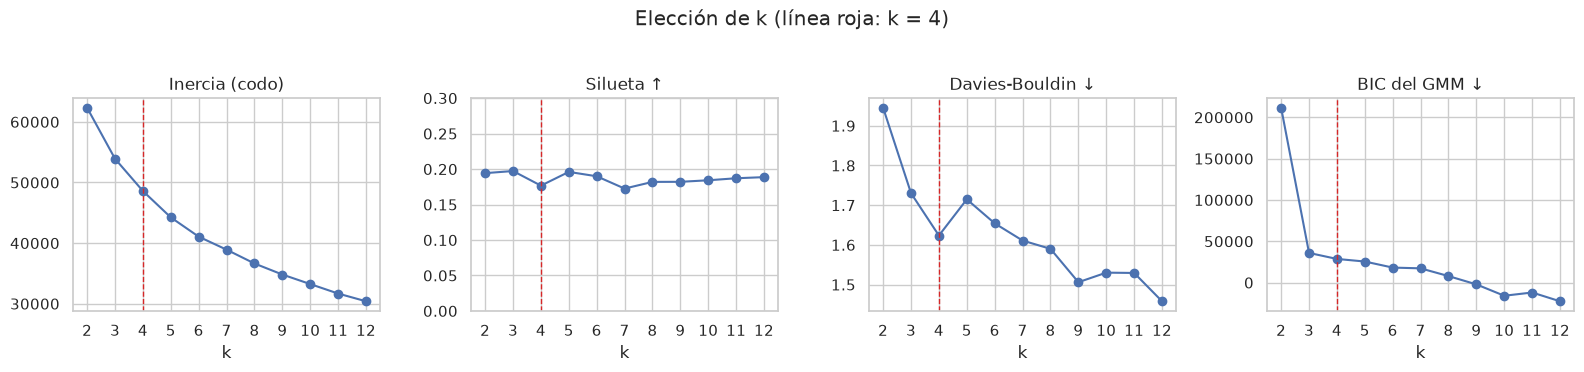

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col, titulo in zip(axes, ["inercia", "silueta", "davies_bouldin", "bic_gmm"],
                           ["Inercia (codo)", "Silueta ↑", "Davies-Bouldin ↓", "BIC del GMM ↓"]):
    ax.plot(eleccion.index, eleccion[col], marker="o")
    ax.axvline(K_ELEGIDO, color="tab:red", ls="--", lw=1)
    ax.set_title(titulo); ax.set_xlabel("k"); ax.set_xticks(range(2, 13))
axes[1].set_ylim(0, 0.3)
plt.suptitle(f"Elección de k (línea roja: k = {K_ELEGIDO})", y=1.03)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_eleccion_k.png", dpi=120, bbox_inches="tight"); plt.show()

**Lectura honesta:**
- **Silueta baja para todo k (≈ 0.17–0.20)**: no hay grupos bien separados. Las horas forman un continuo (la temperatura y la humedad varían suavemente), no "nubes" aisladas. La silueta sola **no** elige k: k = 2, 3 y 5 empatan dentro de ±0.005.
- **Inercia** sin codo claro; **Davies-Bouldin** baja lento con k.
- **BIC del GMM** baja sin parar (incluso negativo desde k = 9): con covarianza completa, más componentes siempre describen mejor una densidad continua. El BIC tampoco da un k.

Conclusión: los índices internos **no** justifican un k por sí solos. Se decide con **estabilidad** (sección 4) e **interpretabilidad** (sección 6), como pide el plan (§5.3: "decidir con interpretabilidad; k = 4 era conjetura").

## 4) Estabilidad de los clusters

Tres pruebas para k = 2, 4 y 6, medidas con el índice de Rand ajustado (ARI; 1 = misma partición):
1. **Semillas:** K-Means con `random_state` 1, 7 y 123 contra 42.
2. **Bootstrap:** 10 remuestreos del train; cada modelo asigna todas las filas y se compara con el original.
3. **Temporal:** ajustar solo con 2011 y asignar todo el train. Imita lo que pasará con el test (asignar datos de otro periodo).

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
filas = []
for k in [2, 4, 6]:
    base = modelos_km[k].labels_
    semillas = [adjusted_rand_score(base, KMeans(k, n_init=10, random_state=s).fit_predict(Z)) for s in [1, 7, 123]]
    boots = []
    for _ in range(10):
        idx = rng.choice(len(Z), len(Z))
        boots.append(adjusted_rand_score(base, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z.iloc[idx]).predict(Z)))
    solo_2011 = Z.index < "2012-01-01"
    km_2011 = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z[solo_2011])
    filas.append({"k": k, "ARI semillas (mín)": min(semillas), "ARI bootstrap (media)": np.mean(boots),
                  "ARI bootstrap (mín)": min(boots), "ARI 2011 → todo": adjusted_rand_score(base, km_2011.predict(Z))})
estabilidad = pd.DataFrame(filas).set_index("k").round(3)
estabilidad

,ARI semillas (mín),ARI bootstrap (media),ARI bootstrap (mín),ARI 2011 → todo
k,,,,
2,0.990,0.968,0.937,0.876
4,0.997,0.950,0.864,0.955
6,0.981,0.936,0.874,0.805


**Lectura:** k = 4 es el más estable **en el tiempo** (ajustado solo con 2011 reproduce ≈ 0.95 de la partición), y prácticamente insensible a la semilla. k = 6 pierde estabilidad temporal (≈ 0.80): parte de sus fronteras dependen del periodo. k = 2 es estable pero solo separa "noche/mañana húmeda" de "tarde seca", poco útil para el análisis de errores.

**Decisión: k = 4** (estable y, como se ve abajo, interpretable). Sigue siendo una **partición útil**, no una estructura natural fuerte (silueta ≈ 0.18).

## 5) GMM como comparación

In [7]:
km4, gmm4 = modelos_km[K_ELEGIDO], modelos_gmm[K_ELEGIDO]
lab_km, lab_gmm = km4.labels_, gmm4.predict(Z)
proba = gmm4.predict_proba(Z).max(axis=1)
print(f"ARI K-Means vs GMM (k={K_ELEGIDO}): {adjusted_rand_score(lab_km, lab_gmm):.3f}")
print(f"GMM: % de horas con probabilidad máxima < 0.8 (asignación dudosa): {(proba < 0.8).mean():.1%}")
pd.crosstab(pd.Series(lab_km, name="K-Means"), pd.Series(lab_gmm, name="GMM"))

ARI K-Means vs GMM (k=4): 0.442
GMM: % de horas con probabilidad máxima < 0.8 (asignación dudosa): 0.0%


GMM,0,1,2,3
K-Means,,,,
0,726,1579,676,514
1,0,133,3000,0
2,3373,0,0,0
3,0,160,1860,982


El GMM con covarianza completa arma grupos distintos (ARI ≈ 0.44): solo coincide en aislar las horas no laborables. Además asigna casi todas las horas con probabilidad > 0.8, no porque los grupos estén bien separados sino porque `workingday` es binaria y la covarianza completa la aprovecha como dos "planos" casi degenerados. Se mantiene **K-Means como técnica principal** (§5.2) y el GMM queda como contraste.

## 6) Interpretación de los centroides (k = 4)

In [8]:
pipe_clu = build_clustering(K_ELEGIDO).fit(X_tr)
etiquetas = pd.Series(pipe_clu.predict(X_tr), index=X_tr.index, name="cluster")
assert adjusted_rand_score(etiquetas, lab_km) > 0.999   # el pipeline reproduce el modelo de la sección 3

# Centroides en unidades originales (se deshace el escalado; la hora se recupera del ángulo)
centros = pd.DataFrame(pipe_clu.named_steps["scaler"].inverse_transform(pipe_clu.named_steps["kmeans"].cluster_centers_),
                       columns=VARIABLES)
centros["hora_centro"] = (np.degrees(np.arctan2(centros.hr_sin, centros.hr_cos)) % 360 / 15).round(1)
centros["temp_c"] = (centros.temp * 41).round(1)

# El target SOLO para interpretar (no entró al clustering)
perfil = pd.DataFrame({"cluster": etiquetas, "cnt": y_tr, "hr": X_tr.hr, "weathersit": X_tr.weathersit}).groupby("cluster").agg(
    horas=("cnt", "size"), cnt_media=("cnt", "mean"), cnt_mediana=("cnt", "median"),
    hora_mediana=("hr", "median"), pct_lluvia=("weathersit", lambda s: (s >= 3).mean() * 100))
interpretacion = centros[["hora_centro", "temp_c", "hum", "windspeed", "workingday"]].join(perfil).round(2)
interpretacion

,hora_centro,temp_c,hum,windspeed,workingday,horas,cnt_media,cnt_mediana,hora_mediana,pct_lluvia
0,14.8,23.6,0.44,0.28,0.79,3495,278.24,233.0,15.0,3.43
1,7.1,17.9,0.74,0.16,1.00,3133,137.94,96.0,7.0,12.93
2,3.0,18.0,0.66,0.17,-0.00,3373,125.24,78.0,9.0,7.92
3,22.4,19.2,0.69,0.16,1.00,3002,117.83,72.0,19.0,11.33


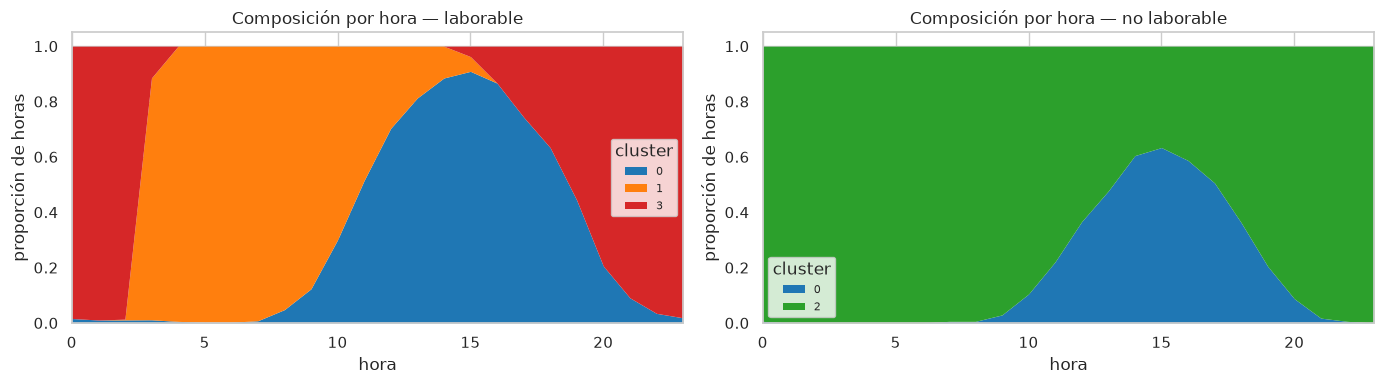

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
COLORES = dict(zip(range(K_ELEGIDO), sns.color_palette("tab10", K_ELEGIDO)))
for ax, wd in zip(axes, [1, 0]):
    sub = pd.crosstab(X_tr.hr[X_tr.workingday == wd], etiquetas[X_tr.workingday == wd], normalize="index")
    sub.plot.area(ax=ax, stacked=True, color=[COLORES[c] for c in sub.columns], lw=0)
    ax.set_title(f"Composición por hora — {'laborable' if wd else 'no laborable'}")
    ax.set_xlabel("hora"); ax.set_ylabel("proporción de horas"); ax.set_xlim(0, 23); ax.legend(title="cluster", fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_clusters_por_hora.png", dpi=120); plt.show()

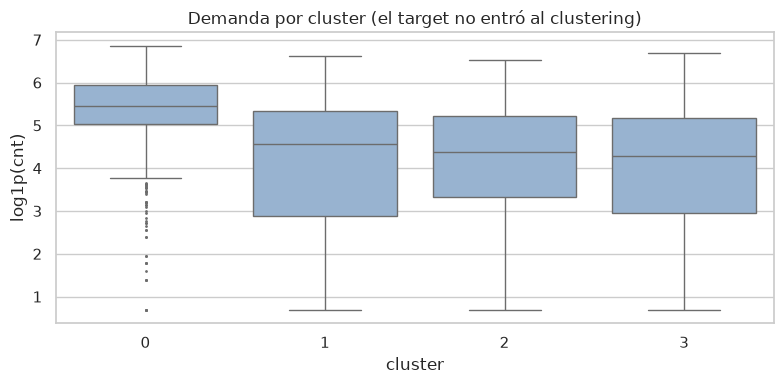

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=etiquetas, y=np.log1p(y_tr), ax=ax, color="#8fb3d9", fliersize=1)
ax.set_xlabel("cluster"); ax.set_ylabel("log1p(cnt)"); ax.set_title("Demanda por cluster (el target no entró al clustering)")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_demanda_por_cluster.png", dpi=120); plt.show()

**Arquetipos** (nombres propuestos a partir de la tabla de centroides y de la figura de composición):

| Cluster | Nombre propuesto | Qué lo define (centroide) | Demanda media |
| :---: | :--- | :--- | :---: |
| 0 | **Tarde cálida y seca** | ~15 h, 23.6 °C, humedad 0.44, más viento; 79 % laborable (incluye tardes de fin de semana) | **278** |
| 1 | **Mañana laborable** | laborable, ~7 h (de 3 a 14 h), 17.9 °C, húmeda | 138 |
| 2 | **No laborable (salvo tardes cálidas)** | `workingday` = 0, resto del día | 125 |
| 3 | **Noche laborable** | laborable, centro ~22 h (de 17 a 2 h), húmeda | 118 |

Observaciones:
- El cluster 0 **cruza el tipo de día**: la tarde cálida pesa más que `workingday` en la distancia.
- 🔶 Lo esperado en el plan (§5.4) se cumple a medias: no aparece un cluster de **clima adverso** (la lluvia no es entrada; solo se nota indirecta: 3 % de horas con lluvia en el cluster 0 vs. 11–13 % en 1 y 3) y el pico de las 8 h queda dentro de "mañana laborable" junto con la madrugada. Son límites de las entradas elegidas, no hallazgos sobre el uso.

## 7) ¿Cuánto de la demanda explican los clusters?

In [11]:
ly = np.log1p(y_tr)
def eta2(grupos):
    """Proporción de la varianza de log1p(cnt) explicada por una agrupación (R² de las medias por grupo)."""
    medias = ly.groupby(grupos).transform("mean")
    return 1 - ((ly - medias) ** 2).sum() / ((ly - ly.mean()) ** 2).sum()

comparacion = pd.Series({
    f"clusters K-Means k={K_ELEGIDO}": eta2(etiquetas),
    "clusters K-Means k=6": eta2(pd.Series(modelos_km[6].labels_, index=X_tr.index)),
    "workingday (2 grupos)": eta2(X_tr.workingday),
    "hr (24 grupos)": eta2(X_tr.hr),
    "hr × workingday (48 grupos, baseline)": eta2(X_tr.hr.astype(str) + "_" + X_tr.workingday.astype(str)),
}, name="varianza de log1p(cnt) explicada").round(3)
comparacion

clusters K-Means k=4                     0.175
clusters K-Means k=6                     0.271
workingday (2 grupos)                    0.000
hr (24 grupos)                           0.705
hr × workingday (48 grupos, baseline)    0.809
Name: varianza de log1p(cnt) explicada, dtype: float64

**Lectura:** los 4 clusters explican el 17.5 % de la varianza de `log1p(cnt)`, frente al 81 % de hora × `workingday`. Son útiles para **describir** y para **segmentar el error** (Sprint 3), no como variable predictora ni como "tipos reales" de usuario. No se agregan como feature al supervisado.

## 8) PCA: varianza y *loadings*

In [12]:
pca = PCA(random_state=RANDOM_STATE).fit(Z)
varianza = pd.DataFrame({"varianza": pca.explained_variance_ratio_, "acumulada": pca.explained_variance_ratio_.cumsum()},
                        index=[f"PC{i+1}" for i in range(Z.shape[1])]).round(3)
loadings = pd.DataFrame(pca.components_[:3].T, index=VARIABLES, columns=["PC1", "PC2", "PC3"]).round(2)
display(varianza.T)
loadings

,PC1,PC2,PC3,PC4,PC5,PC6
varianza,0.282,0.181,0.168,0.160,0.121,0.088
acumulada,0.282,0.463,0.631,0.791,0.912,1.000


,PC1,PC2,PC3
hr_sin,0.49,-0.26,-0.55
hr_cos,0.36,0.12,0.70
temp,-0.24,0.71,-0.03
hum,0.60,0.16,-0.08
windspeed,-0.46,-0.33,-0.11
workingday,0.00,0.53,-0.44


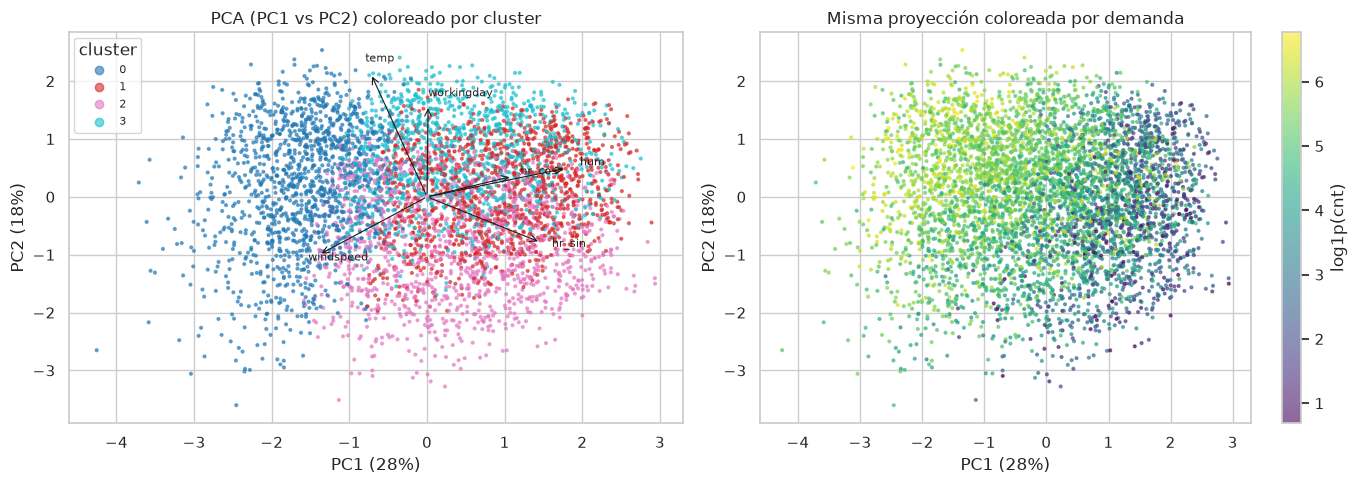

In [13]:
P = pca.transform(Z)[:, :2]
muestra = np.random.default_rng(RANDOM_STATE).choice(len(Z), 5000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc = axes[0].scatter(P[muestra, 0], P[muestra, 1], c=etiquetas.to_numpy()[muestra], cmap="tab10", s=4, alpha=0.6)
axes[0].legend(*sc.legend_elements(), title="cluster", fontsize=8)
axes[0].set_title("PCA (PC1 vs PC2) coloreado por cluster")
for v, (a, b) in zip(VARIABLES, pca.components_[:2].T):
    axes[0].annotate("", xy=(a * 3, b * 3), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=0.8))
    axes[0].text(a * 3.3, b * 3.3, v, fontsize=8)
sc2 = axes[1].scatter(P[muestra, 0], P[muestra, 1], c=np.log1p(y_tr.to_numpy()[muestra]), cmap="viridis", s=4, alpha=0.6)
plt.colorbar(sc2, ax=axes[1], label="log1p(cnt)")
axes[1].set_title("Misma proyección coloreada por demanda")
for ax in axes: ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_pca.png", dpi=120); plt.show()

**Lectura:** la varianza está repartida (PC1 ≈ 28 %, hacen falta 4 componentes para ~79 %): las 6 variables aportan información poco redundante y la reducción a 2D pierde mucho. PC1 opone **humedad/madrugada** a **viento/tarde** (ciclo diario del clima); PC2 es **temperatura + `workingday`**. La demanda (derecha) crece hacia la zona de tarde cálida, coherente con el cluster de mayor demanda.

## 9) UMAP: visualización 2D

Solo para visualizar (lab6). Sobre una muestra de 5 000 horas de train, `random_state=42` (UMAP fija `n_jobs=1` para ser reproducible). Las distancias entre grupos en UMAP **no** son interpretables; la vecindad local sí.

/root/bike-sharing-ml/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


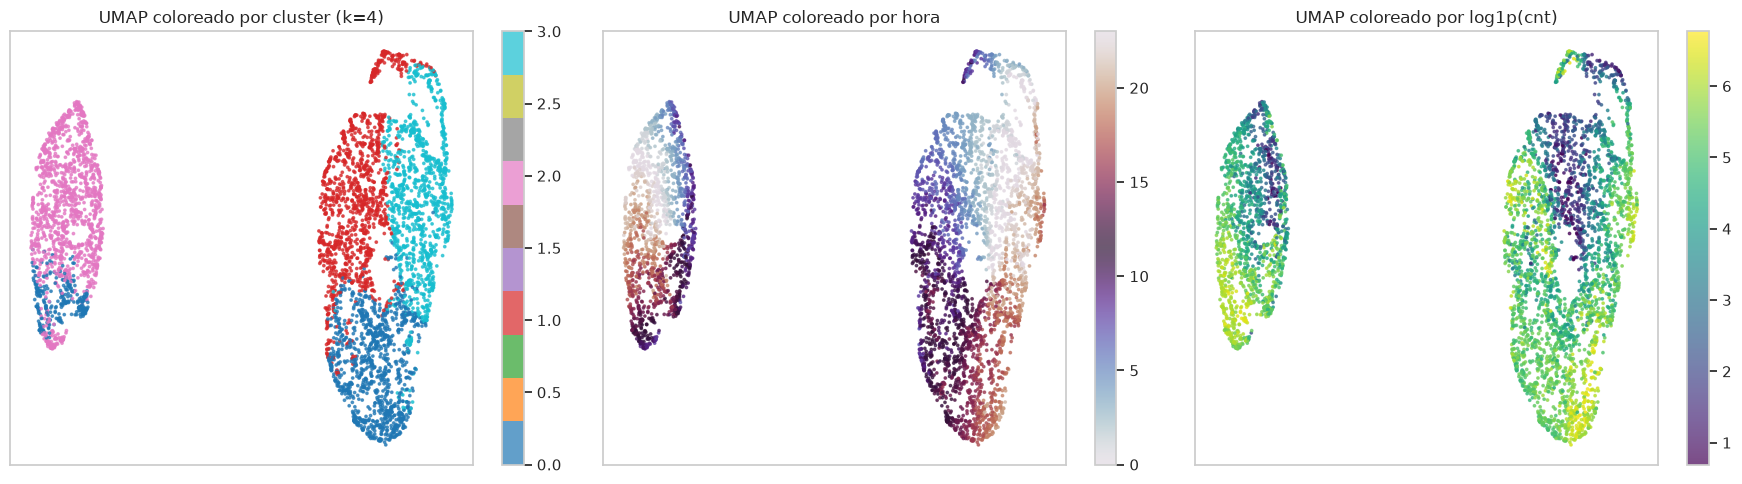

In [14]:
import umap

reductor = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE)
U = reductor.fit_transform(Z.iloc[muestra])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, color, titulo, cmap in [(axes[0], etiquetas.to_numpy()[muestra], "cluster (k=4)", "tab10"),
                                (axes[1], X_tr.hr.to_numpy()[muestra], "hora", "twilight"),
                                (axes[2], np.log1p(y_tr.to_numpy()[muestra]), "log1p(cnt)", "viridis")]:
    s = ax.scatter(U[:, 0], U[:, 1], c=color, cmap=cmap, s=3, alpha=0.7)
    plt.colorbar(s, ax=ax); ax.set_title(f"UMAP coloreado por {titulo}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG_DIR / "07_umap.png", dpi=120); plt.show()

**Lectura:** UMAP separa dos bloques por `workingday` (variable binaria) y, dentro de cada uno, un gradiente continuo por hora. Los clusters de K-Means cortan esos bloques en tramos contiguos, no en islas: es una **partición de un continuo**, coherente con la silueta baja. La demanda (derecha) también varía de forma gradual y no se alinea del todo con los cortes.

## 10) Guardado del modelo de clustering (para el Sprint 3)

In [15]:
ruta = CONFIG["dir_models"] / "clustering_pardo.joblib"
joblib.dump({"pipeline": pipe_clu, "k": K_ELEGIDO, "variables": VARIABLES}, ruta)
recargado = joblib.load(ruta)["pipeline"]
assert (recargado.predict(X_tr) == etiquetas.to_numpy()).all()
print(f"✅ Guardado y recarga verificada: {ruta.relative_to(RAIZ)}")
print("Uso en el Sprint 3:  joblib.load(...)['pipeline'].predict(X)  -> cluster de cada hora (X de separar_xy)")

✅ Guardado y recarga verificada: models/clustering_pardo.joblib
Uso en el Sprint 3:  joblib.load(...)['pipeline'].predict(X)  -> cluster de cada hora (X de separar_xy)


### ✅ Punto de control final

In [16]:
assert estabilidad.loc[K_ELEGIDO, "ARI 2011 → todo"] > 0.9
assert eleccion["silueta"].max() < 0.3
print(f"✅ k = {K_ELEGIDO}: silueta {eleccion.loc[K_ELEGIDO, 'silueta']:.3f}, "
      f"ARI temporal {estabilidad.loc[K_ELEGIDO, 'ARI 2011 → todo']:.3f}, "
      f"varianza de log1p(cnt) explicada {comparacion.iloc[0]:.1%}.")

✅ k = 4: silueta 0.177, ARI temporal 0.955, varianza de log1p(cnt) explicada 17.5%.


## 11) Conclusiones (Sprint 2, Pardo)

1. **No hay clusters naturales fuertes** en las 6 variables (silueta ≈ 0.18 para todo k; BIC del GMM sin mínimo). Se reporta así, sin forzar una estructura.
2. **k = 4** se elige por **estabilidad** (semillas ARI ≈ 1; ajustado solo con 2011 reproduce ≈ 0.95) e **interpretabilidad**, no por la silueta. k = 6 es menos estable en el tiempo.
3. Arquetipos: tarde cálida y seca (mayor demanda, cruza el tipo de día), mañana laborable, noche laborable y no laborable. No aparece un cluster de clima adverso con estas entradas.
4. Los clusters explican menos varianza de la demanda que hora × `workingday`: **se usan para segmentar el error en el Sprint 3, no como feature**.
5. PCA: varianza repartida (4 componentes para ~79 %); UMAP muestra un continuo partido por `workingday`.

Modelo guardado en `models/clustering_pardo.joblib` (no viaja con git; se regenera ejecutando este notebook en ~1 min). Fichas en `reports/decisiones.md`.